# M5 Demand Forecasting (Simple Version)
**What this does:** takes real Walmart sales, turns them into weekly sales, guesses the last 12 weeks two ways, and checks which guess was closer.

**Before you start:** put `sales_train_evaluation.csv` and `calendar.csv` in the same folder as this notebook. Run each cell with Shift + Enter, top to bottom.

## Step 0: Load the tools

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.holtwinters import ExponentialSmoothing, SimpleExpSmoothing
from statsmodels.tsa.seasonal import seasonal_decompose
import warnings
warnings.filterwarnings("ignore")

## Step 1: Open the files
`sales` has units sold per product per day. `cal` turns day codes like d_1 into real dates.

In [2]:
sales = pd.read_csv("sales_train_evaluation.csv")
cal = pd.read_csv("calendar.csv")
cal["date"] = pd.to_datetime(cal["date"])

print("Rows in sales file:", len(sales))

Rows in sales file: 30490


## Step 2: Keep one store and one category
We only want food products in Texas store TX_1.

In [3]:
df = sales[sales["store_id"] == "TX_1"]
df = df[df["cat_id"] == "FOODS"]

print("Food products in TX_1:", len(df))

Food products in TX_1: 1437


## Step 3: Make a list of the day columns
The day columns are named d_1, d_2, d_3 ... We collect their names in a list.

In [4]:
day_cols = []
for col in df.columns:
    if col.startswith("d_"):
        day_cols.append(col)

print("Number of days:", len(day_cols))

Number of days: 1941


## Step 4: Turn columns into rows
Right now each day is a column. `melt` stacks them so each row is: one product, one day, units sold.

In [5]:
long = df.melt(id_vars="item_id", value_vars=day_cols, var_name="d", value_name="units")
long.head()

,item_id,d,units
0,FOODS_1_001,d_1,0
1,FOODS_1_002,d_1,0
2,FOODS_1_003,d_1,0
3,FOODS_1_004,d_1,0
4,FOODS_1_005,d_1,2


## Step 5: Add real dates and Walmart weeks
We join the calendar on the day code `d`. This works like XLOOKUP.

In [6]:
long = long.merge(cal[["d", "date", "wm_yr_wk"]], on="d")
long.head()

,item_id,d,units,date,wm_yr_wk
0,FOODS_1_001,d_1,0,2011-01-29,11101
1,FOODS_1_002,d_1,0,2011-01-29,11101
2,FOODS_1_003,d_1,0,2011-01-29,11101
3,FOODS_1_004,d_1,0,2011-01-29,11101
4,FOODS_1_005,d_1,2,2011-01-29,11101


## Step 6: Remove incomplete weeks
A Walmart week runs Saturday to Friday. The last week in the data only has 2 days, which would look like a sales drop. We keep only weeks with all 7 days.

In [7]:
days_in_week = long.groupby("wm_yr_wk")["date"].nunique()
full_weeks = days_in_week[days_in_week == 7].index

long = long[long["wm_yr_wk"].isin(full_weeks)]
print("Full weeks kept:", len(full_weeks))

Full weeks kept: 277


## Step 7: Add up daily sales into weekly sales
Like a pivot table: total units for each product in each week.

In [8]:
weekly = long.groupby(["item_id", "wm_yr_wk"])["units"].sum().reset_index()

week_dates = long.groupby("wm_yr_wk")["date"].min().reset_index()
week_dates = week_dates.rename(columns={"date": "week_start"})
weekly = weekly.merge(week_dates, on="wm_yr_wk")

weekly.head()

,item_id,wm_yr_wk,units,week_start
0,FOODS_1_001,11101,2,2011-01-29
1,FOODS_1_002,11101,0,2011-01-29
2,FOODS_1_003,11101,1,2011-01-29
3,FOODS_1_004,11101,0,2011-01-29
4,FOODS_1_005,11101,9,2011-01-29


## Step 8: Find the 20 best-selling products
Add up each product's total sales, sort from highest to lowest, keep the top 20.

In [9]:
totals = weekly.groupby("item_id")["units"].sum()
totals = totals.sort_values(ascending=False)
top_items = list(totals.head(20).index)

print(top_items)

['FOODS_3_586', 'FOODS_3_090', 'FOODS_3_555', 'FOODS_3_252', 'FOODS_3_587', 'FOODS_3_714', 'FOODS_3_202', 'FOODS_3_694', 'FOODS_3_723', 'FOODS_3_607', 'FOODS_3_377', 'FOODS_3_681', 'FOODS_3_226', 'FOODS_2_181', 'FOODS_3_541', 'FOODS_3_808', 'FOODS_3_455', 'FOODS_3_234', 'FOODS_3_462', 'FOODS_3_635']


## Step 9: One column per product
Each row is a week, each column is a product. This makes each product's sales easy to grab: `wide["FOODS_3_586"]`.

In [10]:
weekly = weekly[weekly["item_id"].isin(top_items)]
wide = weekly.pivot(index="week_start", columns="item_id", values="units")
wide = wide.fillna(0)

print("Weeks:", len(wide), "| Products:", len(wide.columns))

Weeks: 277 | Products: 20


## Step 10: Look at the top 5 products
The faint line is weekly sales. The bold line is a 4-week average, which smooths out the noise.

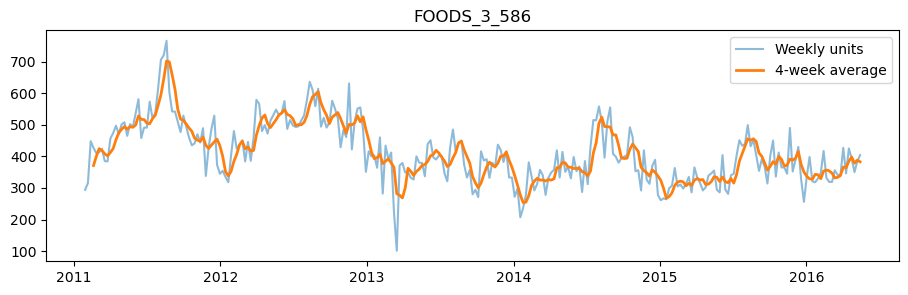

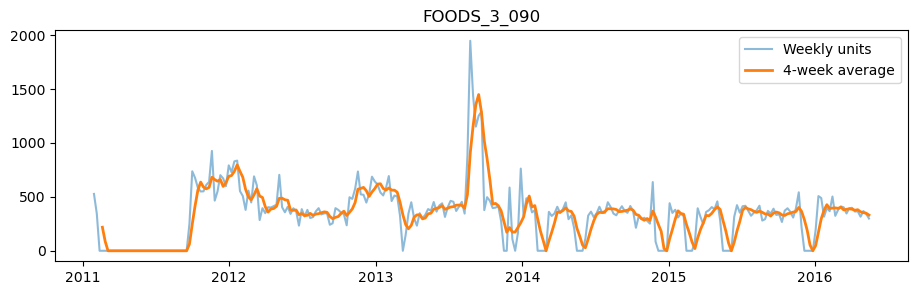

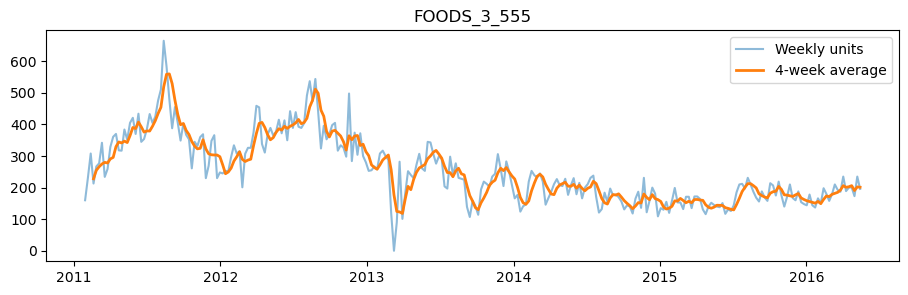

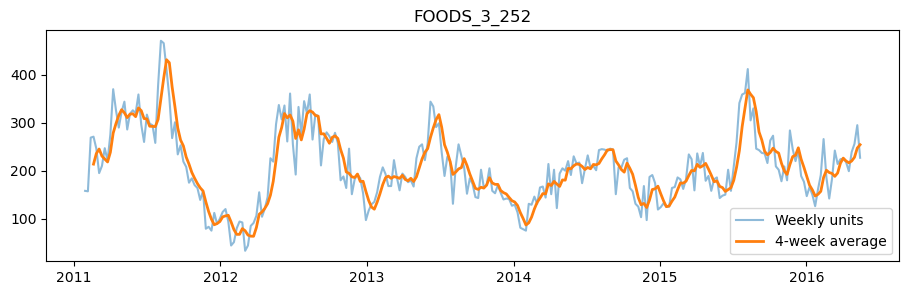

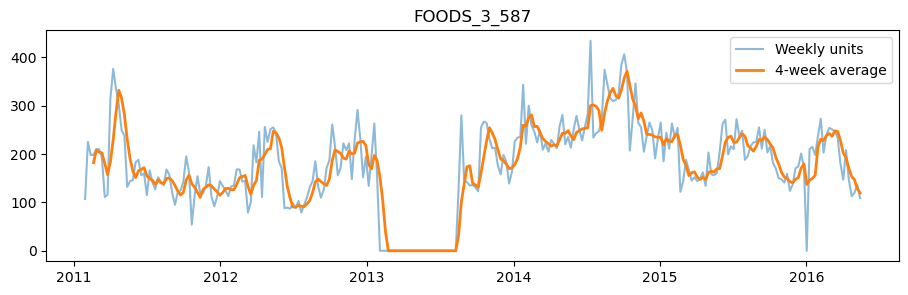

In [11]:
for item in top_items[:5]:
    plt.figure(figsize=(11, 3))
    plt.plot(wide[item], alpha=0.5, label="Weekly units")
    plt.plot(wide[item].rolling(4).mean(), linewidth=2, label="4-week average")
    plt.title(item)
    plt.legend()
    plt.show()

## Step 11: Split the top product into trend, season and noise
- **Trend:** going up or down over the years
- **Seasonal:** the pattern that repeats every year
- **Resid:** random leftover

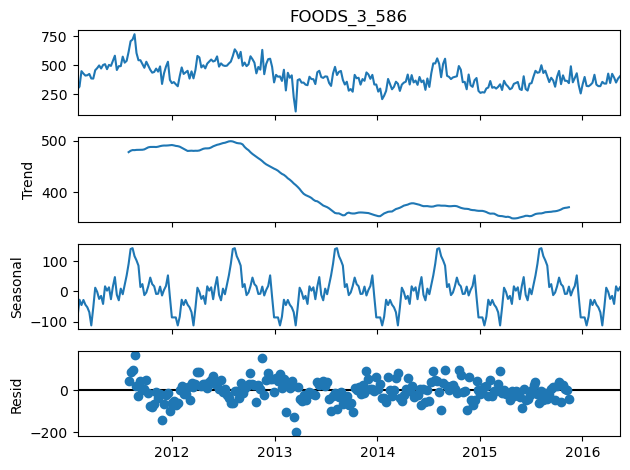

In [12]:
item = top_items[0]
parts = seasonal_decompose(wide[item], model="additive", period=52)
parts.plot()
plt.show()

## Step 12: Hide the last 12 weeks
`train` = weeks the forecast learns from. `test` = the last 12 weeks, kept hidden to check the guess.

In [13]:
sales_history = wide[item]

train = sales_history[:-12]
test = sales_history[-12:]

print("Train weeks:", len(train), "| Test weeks:", len(test))

Train weeks: 265 | Test weeks: 12


## Step 13: Guess #1, moving average
Average the last 4 weeks, and use that same number for all 12 future weeks.

In [14]:
def moving_average_forecast(train, weeks):
    guess = train.tail(4).mean()
    return [guess] * weeks

ma_forecast = moving_average_forecast(train, 12)
print(ma_forecast)

[356.75, 356.75, 356.75, 356.75, 356.75, 356.75, 356.75, 356.75, 356.75, 356.75, 356.75, 356.75]


## Step 14: Guess #2, Holt-Winters
Learns the normal level, the trend and the yearly season. If there's less than 2 years of history, it uses a simpler average instead. Negative guesses are changed to 0.

In [15]:
def holt_winters_forecast(train, weeks):
    if len(train) >= 104:
        model = ExponentialSmoothing(train, trend="add", damped_trend=True,
                                     seasonal="add", seasonal_periods=52).fit()
    else:
        model = SimpleExpSmoothing(train).fit()
    forecast = model.forecast(weeks)
    forecast = forecast.clip(lower=0)
    return list(forecast)

hw_forecast = holt_winters_forecast(train, 12)
print(hw_forecast)

[349.66259816394444, 337.08212121151485, 294.04780106082853, 343.398050885985, 409.99697575869646, 400.3447432418785, 383.58656772931516, 387.79230322940253, 369.3097588495352, 419.91231009850526, 401.25640379341775, 415.86835808894824]


## Step 15: Draw the guesses against what really sold
The closer a dashed line is to the black line, the better the guess.

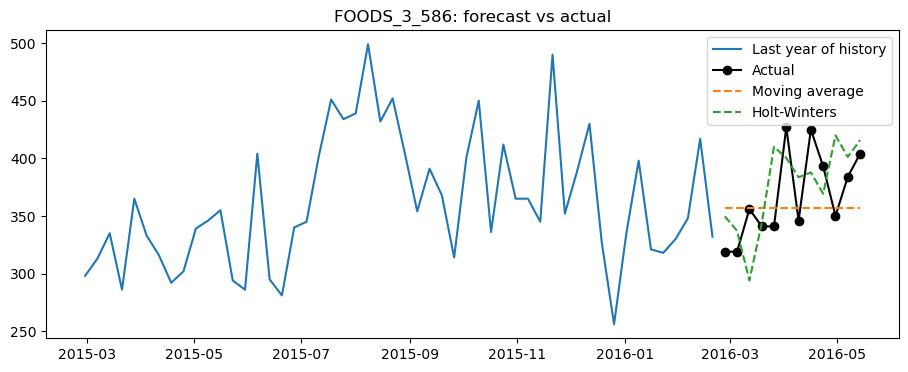

In [16]:
plt.figure(figsize=(11, 4))
plt.plot(train[-52:], label="Last year of history")
plt.plot(test.index, test, "k-o", label="Actual")
plt.plot(test.index, ma_forecast, "--", label="Moving average")
plt.plot(test.index, hw_forecast, "--", label="Holt-Winters")
plt.title(item + ": forecast vs actual")
plt.legend()
plt.show()

## Step 16: Score the guesses
- **MAE:** average units off per week
- **WAPE:** total miss ÷ total sales, in % (main score)
- **MAPE:** average % miss per week (skips zero-sales weeks)
- **Bias:** negative = guessed too low (stockouts), positive = too high (extra stock)

In [17]:
def get_scores(actual, forecast):
    actual = pd.Series(list(actual))
    forecast = pd.Series(list(forecast))

    error = forecast - actual
    miss = error.abs()
    sold = actual != 0

    mae = miss.mean()
    wape = miss.sum() / actual.sum() * 100
    mape = (miss[sold] / actual[sold]).mean() * 100
    bias = error.sum() / actual.sum() * 100

    return {"MAE": mae, "WAPE_%": wape, "MAPE_%": mape, "Bias_%": bias}

print("Moving average:", get_scores(test, ma_forecast))
print("Holt-Winters:  ", get_scores(test, hw_forecast))

Moving average: {'MAE': 31.208333333333332, 'WAPE_%': 8.501702610669694, 'MAPE_%': 8.223171809634445, 'Bias_%': -2.814982973893303}
Holt-Winters:   {'MAE': 33.855731612390194, 'WAPE_%': 9.222900779765775, 'MAPE_%': 9.409556061640096, 'Bias_%': 2.43491469039664}


## Step 17: Do it for all 20 products
Same steps as above, repeated with a loop. Each product becomes one row in a results table.

In [18]:
rows = []

for item in top_items:
    sales_history = wide[item]
    train = sales_history[:-12]
    test = sales_history[-12:]

    ma_scores = get_scores(test, moving_average_forecast(train, 12))
    hw_scores = get_scores(test, holt_winters_forecast(train, 12))

    if hw_scores["WAPE_%"] < ma_scores["WAPE_%"]:
        best = "Holt-Winters"
    else:
        best = "Moving average"

    rows.append({
        "item": item,
        "avg_weekly_units": sales_history.mean(),
        "MA_WAPE_%": ma_scores["WAPE_%"],
        "HW_WAPE_%": hw_scores["WAPE_%"],
        "best_method": best,
        "best_WAPE_%": min(ma_scores["WAPE_%"], hw_scores["WAPE_%"]),
        "HW_Bias_%": hw_scores["Bias_%"],
    })

results = pd.DataFrame(rows)
results = results.sort_values("avg_weekly_units", ascending=False)
results.round(1)

,item,avg_weekly_units,MA_WAPE_%,HW_WAPE_%,best_method,best_WAPE_%,HW_Bias_%
0,FOODS_3_586,411.1,8.5,9.2,Moving average,8.5,2.4
1,FOODS_3_090,342.6,9.6,24.1,Moving average,9.6,21.6
2,FOODS_3_555,253.6,13.0,11.2,Holt-Winters,11.2,-5.3
3,FOODS_3_252,206.6,15.4,10.2,Holt-Winters,10.2,5.2
4,FOODS_3_587,175.8,36.7,46.6,Moving average,36.7,34.5
5,FOODS_3_714,159.5,32.6,23.7,Holt-Winters,23.7,-23.5
6,FOODS_3_202,139.5,9.1,15.7,Moving average,9.1,12.4
7,FOODS_3_694,134.1,19.2,11.5,Holt-Winters,11.5,-10.9
8,FOODS_3_723,116.6,13.3,38.2,Moving average,13.3,38.2
9,FOODS_3_607,104.2,16.4,29.4,Moving average,16.4,-3.8


## Step 18: Summary and save

In [19]:
hw_wins = (results["best_method"] == "Holt-Winters").sum()
print("Holt-Winters won on", hw_wins, "of", len(results), "products")
print("Average WAPE, moving average:", round(results["MA_WAPE_%"].mean(), 1), "%")
print("Average WAPE, Holt-Winters:  ", round(results["HW_WAPE_%"].mean(), 1), "%")

results.round(2).to_csv("week1_forecast_results.csv", index=False)
print("Saved week1_forecast_results.csv")

Holt-Winters won on 7 of 20 products
Average WAPE, moving average: 42.4 %
Average WAPE, Holt-Winters:   68.2 %
Saved week1_forecast_results.csv
